# 02 - Churn-proxy and CLV model walkthrough
Reads artifacts from `make pipeline` (`churn train`, `churn clv`, `churn target`). **Churn = no purchase in the 90 days after a cutoff - a proxy, not an observed cancellation.**

In [1]:
import os, json, duckdb, pandas as pd, numpy as np, matplotlib.pyplot as plt
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
con = duckdb.connect('data/processed/grocery.duckdb', read_only=True)
art = 'artifacts/'

## Time-aware design
Train on 4 early snapshot cutoffs, choose hyper-parameters and the calibrator on 2017-07-02, report on 2017-10-01. Every label window closes before the next split's cutoff.

In [2]:
tr = pd.read_parquet(art + 'snapshot_train.parquet'); va = pd.read_parquet(art + 'snapshot_valid.parquet')
te = pd.read_parquet(art + 'snapshot_test.parquet')
pd.DataFrame({'rows': [len(tr), len(va), len(te)], 'churn_rate': [tr.churned.mean(), va.churned.mean(), te.churned.mean()],
              'positives': [tr.churned.sum(), va.churned.sum(), te.churned.sum()]},
             index=['train (4 cutoffs)', 'valid 2017-07-02', 'test 2017-10-01'])

,rows,churn_rate,positives
train (4 cutoffs),8704,0.033203,289
valid 2017-07-02,2297,0.043535,100
test 2017-10-01,2314,0.038462,89


In [3]:
tr.groupby('cutoff').churned.agg(['size', 'mean'])

,size,mean
cutoff,,
2017-02-12,2078,0.028393
2017-02-26,2148,0.028864
2017-03-12,2218,0.036069
2017-03-26,2260,0.038938


## Leakage check in-notebook
Features at a cutoff are computed only from rows dated before it.

In [4]:
from churn_clv.features import build_snapshot, FEATURE_COLUMNS
s = build_snapshot(con, '2017-10-01')
last = con.execute("SELECT household_id, MAX(visit_date) d FROM fct_days WHERE visit_date < DATE '2017-10-01' GROUP BY 1").df()
chk = s.merge(last, on='household_id')
assert ((pd.Timestamp('2017-10-01') - pd.to_datetime(chk.d)).dt.days == chk.recency_days).all()
print('recency consistent with pre-cutoff data only;', len(FEATURE_COLUMNS), 'rate/share/fixed-window features')

recency consistent with pre-cutoff data only; 30 rate/share/fixed-window features


## Metrics vs baselines (test cutoff)

In [5]:
pd.read_csv(art + 'model_metrics.csv').query('split=="test"').round(4)

,model,calibration,split,roc_auc,pr_auc,brier,log_loss,ece,calib_slope,calib_intercept,mean_pred,lift_top10,lift_top20,gain_top20,gain_top30,base_rate
1,Recency rule,none,test,0.7928,0.1441,0.0342,0.1382,0.0008,0.9368,-0.1830,0.0392,4.8190,3.2570,0.6517,0.7528,0.0385
3,RFM heuristic,none,test,0.8064,0.1234,0.0347,0.1449,0.0027,0.6574,-0.8284,0.0357,4.0345,2.9762,0.5955,0.7865,0.0385
5,Logistic regression,none,test,0.8407,0.1522,0.0347,0.1367,0.0117,0.7290,-0.4154,0.0297,4.1466,3.5940,0.7191,0.8315,0.0385
6,Logistic regression,isotonic,test,0.8406,0.1437,0.0354,0.1391,0.0121,0.6532,-0.9270,0.0450,4.0345,3.4255,0.6854,0.8202,0.0385
7,Logistic regression,platt,test,0.8407,0.1522,0.0350,0.1349,0.0067,0.7859,-0.6409,0.0444,4.1466,3.5940,0.7191,0.8315,0.0385
9,LightGBM,none,test,0.8431,0.1608,0.0345,0.1329,0.0109,0.9449,0.1042,0.0308,4.0345,3.5940,0.7191,0.8427,0.0385
10,LightGBM,isotonic,test,0.8465,0.1525,0.0352,0.1460,0.0120,0.4099,-1.4173,0.0441,4.2586,3.5940,0.7191,0.8202,0.0385
11,LightGBM,platt,test,0.8431,0.1608,0.0355,0.1340,0.0148,0.7754,-0.6432,0.0436,4.0345,3.5940,0.7191,0.8427,0.0385


In [6]:
pd.read_csv(art + 'test_metric_ci.csv').round(3)

,model,roc_auc,roc_auc_lo,roc_auc_hi,pr_auc,pr_auc_lo,pr_auc_hi
0,Recency rule,0.793,0.741,0.847,0.144,0.104,0.190
1,RFM heuristic,0.806,0.764,0.849,0.123,0.091,0.163
2,Logistic regression,0.841,0.803,0.875,0.152,0.114,0.210
3,Logistic regression + isotonic,0.841,0.804,0.874,0.144,0.108,0.194
4,Logistic regression + platt,0.841,0.803,0.875,0.152,0.114,0.210
5,LightGBM,0.843,0.804,0.878,0.161,0.118,0.222
6,LightGBM + isotonic,0.846,0.811,0.879,0.152,0.116,0.202
7,LightGBM + platt,0.843,0.804,0.878,0.161,0.118,0.222


In [7]:
json.load(open(art + 'train_summary.json'))['paired_bootstrap_test']

{'lightgbm_minus_logreg_roc_auc': {'diff': 0.0024214114379497165,
  'lo': -0.01241811934814221,
  'hi': 0.017044759570847876,
  'share_a_better': 0.635},
 'lightgbm_minus_logreg_pr_auc': {'diff': 0.008605526377087308,
  'lo': -0.012084351175599936,
  'hi': 0.039879075634783163,
  'share_a_better': 0.781},
 'logreg_minus_rfm_roc_auc': {'diff': 0.034346673399823224,
  'lo': 0.015461793730261703,
  'hi': 0.05462730736220814,
  'share_a_better': 1.0},
 'logreg_minus_rfm_pr_auc': {'diff': 0.028766329451706513,
  'lo': 0.0070357122432720175,
  'hi': 0.06603492272582831,
  'share_a_better': 0.999}}

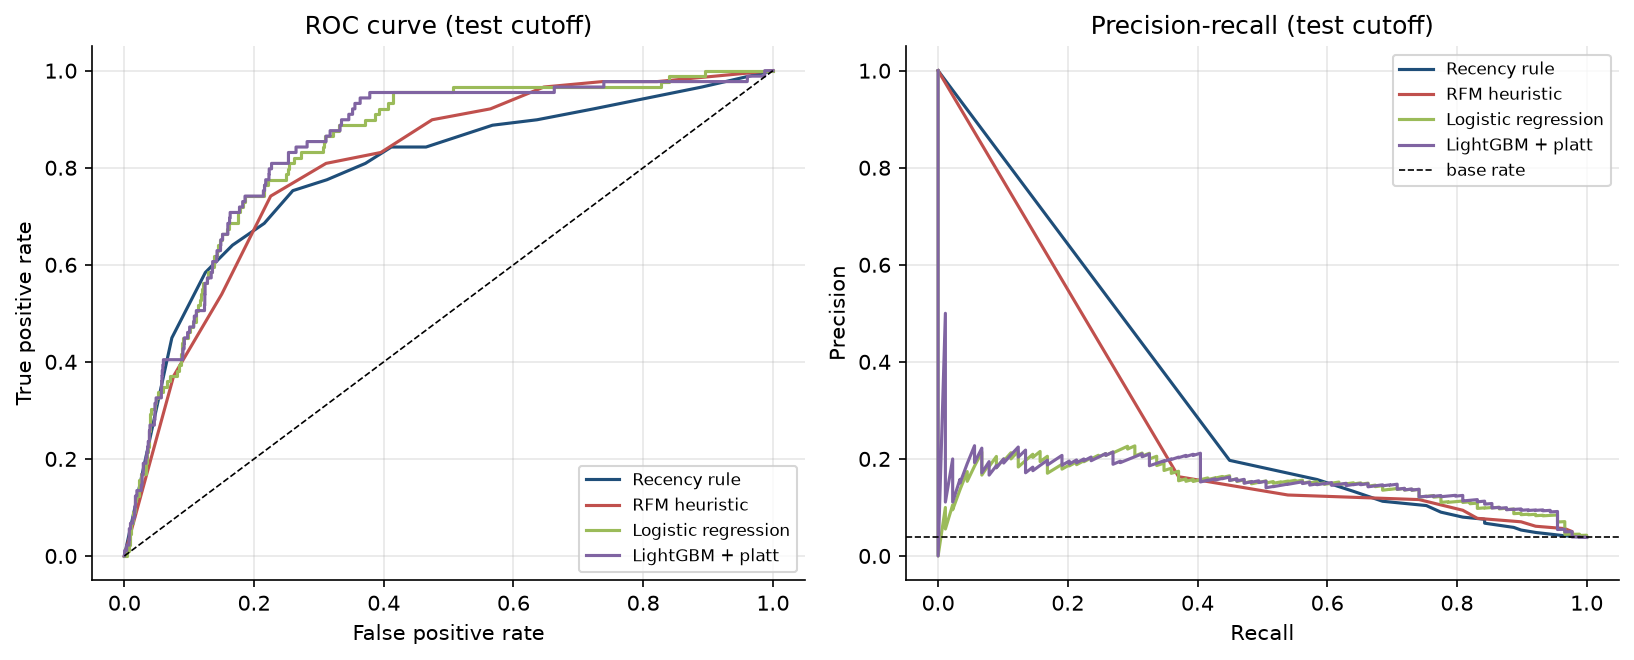

In [8]:
from IPython.display import Image; Image('docs/figures/roc_pr_test.png', width=850)

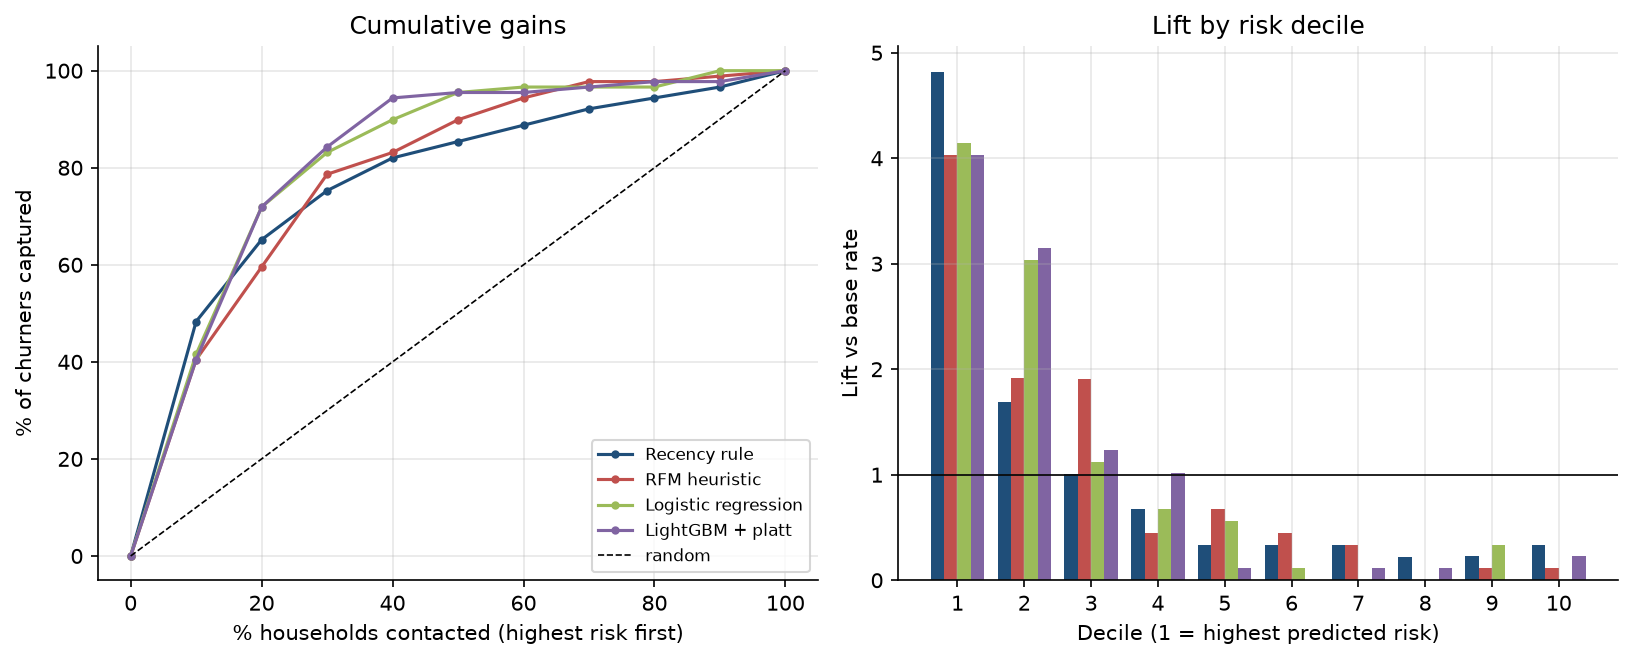

In [9]:
Image('docs/figures/gains_lift_test.png', width=850)

## Calibration
Platt scaling was chosen on validation; isotonic is ineligible with so few positives. Calibration here changes the average level but does not improve Brier on test.

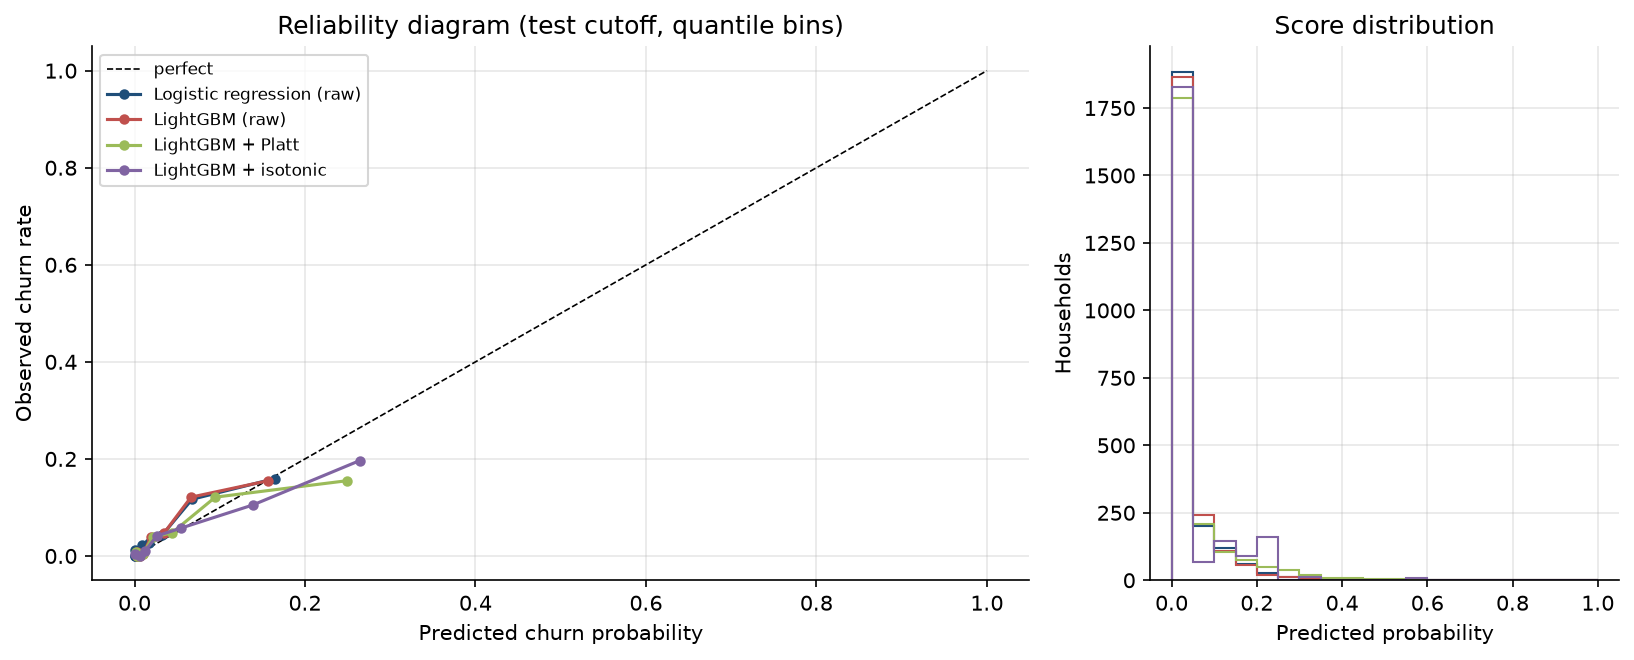

In [10]:
Image('docs/figures/reliability_test.png', width=850)

In [11]:
json.load(open(art + 'train_summary.json'))['calibration']

{'Logistic regression': {'cv_brier_on_valid': {'isotonic': 0.03700790392322086,
   'platt': 0.036877009699900695,
   'none': 0.03733665900833972},
  'isotonic_eligible': False,
  'valid_positives': 100,
  'chosen': 'platt'},
 'LightGBM': {'cv_brier_on_valid': {'isotonic': 0.03574091198676714,
   'platt': 0.0359592696595971,
   'none': 0.0364564673172093},
  'isotonic_eligible': False,
  'valid_positives': 100,
  'chosen': 'platt'}}

In [12]:
json.load(open(art + 'train_summary.json'))['calibration_in_the_large_test']

{'Recency rule': {'mean_pred': 0.03923280329366372,
  'observed': 0.038461538461538464},
 'RFM heuristic': {'mean_pred': 0.03574692065024716,
  'observed': 0.038461538461538464},
 'Logistic regression': {'mean_pred': 0.02973762201243272,
  'observed': 0.038461538461538464},
 'Logistic regression + isotonic': {'mean_pred': 0.04495101606630074,
  'observed': 0.038461538461538464},
 'Logistic regression + platt': {'mean_pred': 0.044411987955056846,
  'observed': 0.038461538461538464},
 'LightGBM': {'mean_pred': 0.03083869463771769,
  'observed': 0.038461538461538464},
 'LightGBM + isotonic': {'mean_pred': 0.04407496698345409,
  'observed': 0.038461538461538464},
 'LightGBM + platt': {'mean_pred': 0.04364779750676693,
  'observed': 0.038461538461538464}}

## Rolling-origin backtest

In [13]:
pd.read_csv(art + 'backtest_metrics.csv')[['eval_cutoff','n_train_snapshots','model','n_eval_positives','roc_auc','pr_auc','brier']].round(3)

,eval_cutoff,n_train_snapshots,model,n_eval_positives,roc_auc,pr_auc,brier
0,2017-06-18,3,Recency rule,98,0.793,0.144,0.038
1,2017-06-18,3,RFM heuristic,98,0.854,0.161,0.037
2,2017-06-18,3,Logistic regression,98,0.863,0.201,0.037
3,2017-06-18,3,LightGBM,98,0.885,0.221,0.037
4,2017-07-16,5,Recency rule,103,0.849,0.198,0.038
5,2017-07-16,5,RFM heuristic,103,0.888,0.209,0.038
6,2017-07-16,5,Logistic regression,103,0.900,0.288,0.037
7,2017-07-16,5,LightGBM,103,0.907,0.286,0.037
8,2017-08-13,7,Recency rule,102,0.838,0.204,0.038
9,2017-08-13,7,RFM heuristic,102,0.888,0.207,0.038


## SHAP explanations

In [14]:
pd.read_csv(art + 'shap_importance.csv').head(10)

,feature,mean_abs_shap
0,trips_per_week,0.493380
1,trips_42d,0.271199
2,trips_28d,0.153427
3,share_fresh,0.133303
4,spend_28d,0.117374
5,top_store_share,0.113633
6,spend_per_week,0.108684
7,spend_42d,0.096155
8,recency_days,0.085919
9,std_interpurchase_days,0.065818


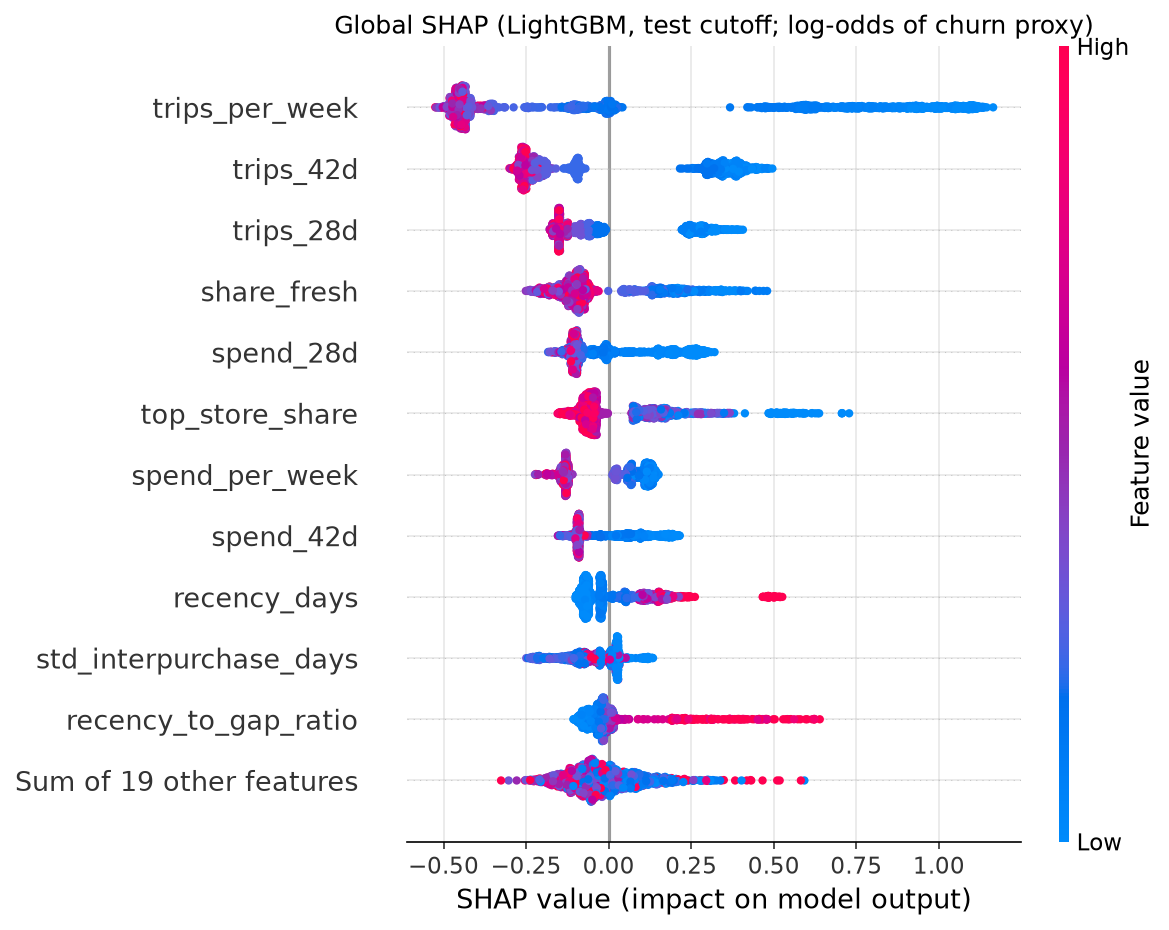

In [15]:
Image('docs/figures/shap_beeswarm.png', width=700)

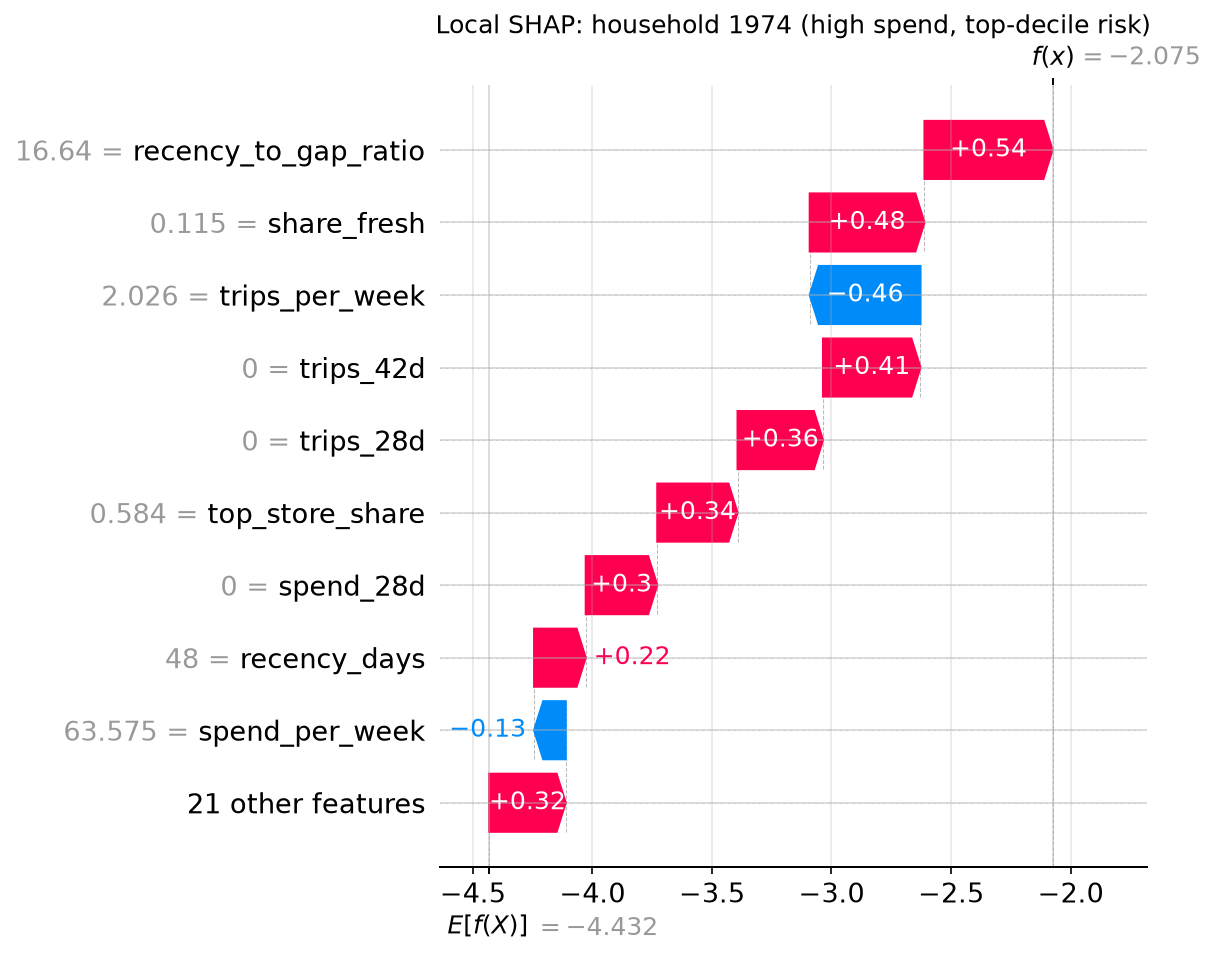

In [16]:
Image('docs/figures/shap_local_waterfall.png', width=700)

## CLV: BG/NBD + Gamma-Gamma holdout validation

In [17]:
{k: v for k, v in json.load(open(art + 'clv_summary.json')).items() if not isinstance(v, dict)}

{'calibration_end': '2017-07-02',
 'observation_end': '2017-12-31',
 'calibration_days': 182.0,
 'holdout_days': 182.0,
 'n_households': 2394,
 'actual_purchases_total': 63212.0,
 'pred_purchases_total': 64058.810978881884,
 'purchases_mae': 8.82342721664449,
 'purchases_corr': 0.8371336402327113,
 'purchases_spearman': 0.813890498074021,
 'baseline_mae_mean_rate': 17.740063050971905,
 'actual_spend_total': 2293540.92,
 'pred_spend_total': 2296054.3077877704,
 'spend_corr': 0.8655340840725833,
 'spend_spearman': 0.8137087064597004,
 'aov_corr_repeaters': 0.730980701644619,
 'gg_freq_spend_corr': -0.020539703692193597,
 'naive_rate_mae': 8.96112326599197,
 'naive_rate_pred_total': 64373.353778261655,
 'top10_share_of_actual_spend': 0.32105707100268344,
 'scoring_as_of': '2017-10-01',
 'clv_12m_total_scored': 4228132.027419942,
 'clv_12m_median': 1163.5059134316625,
 'n_scored_all_households': 2446}

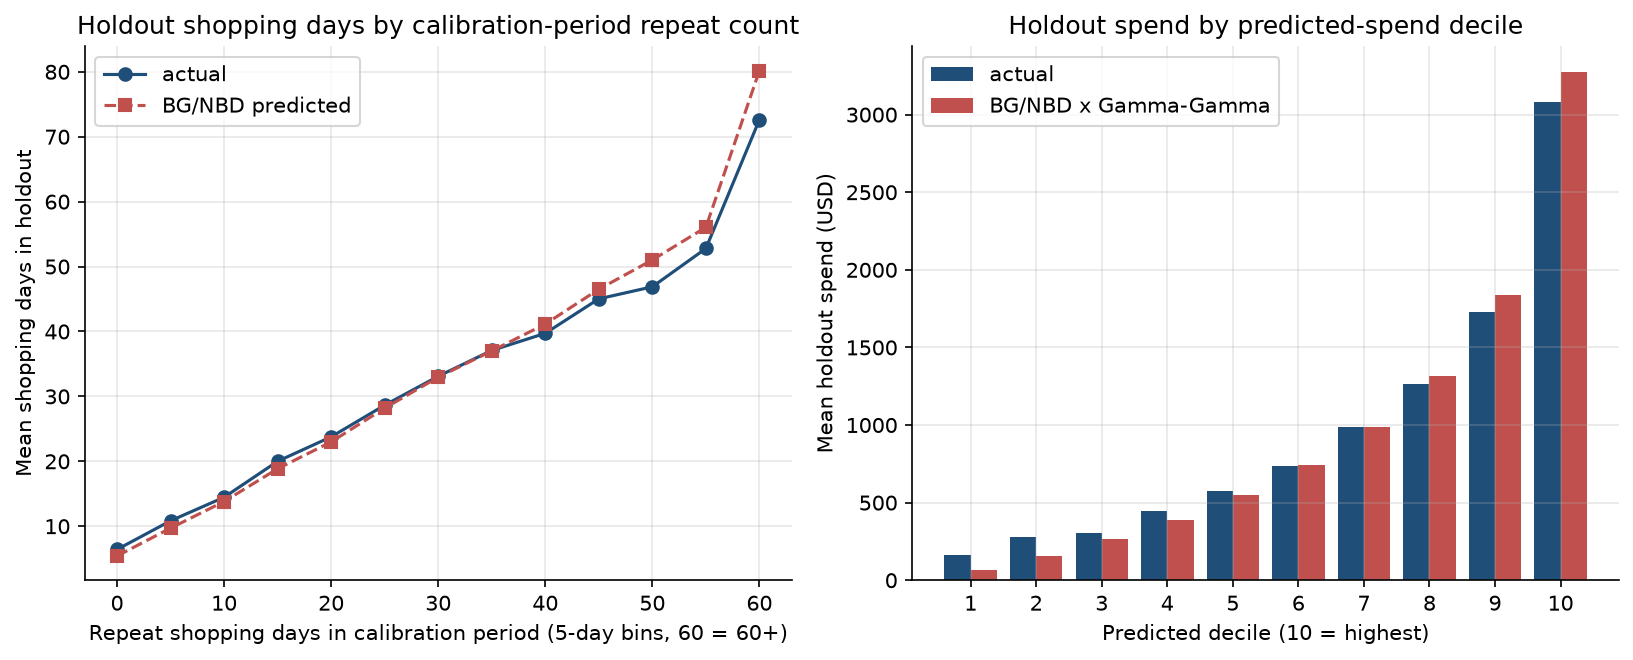

In [18]:
Image('docs/figures/clv_holdout_validation.png', width=850)

## Targeting matrix and ROI rule (ASSUMED parameters)

In [19]:
pd.read_csv(art + 'targeting_matrix.csv').round(2)

,value_segment,risk_segment,households,mean_churn_prob,mean_clv_12m,total_clv_12m,observed_churn_rate,observed_spend_90d
0,Low value,Low risk,35,0.00,1080.88,37830.84,0.00,13748.19
1,Low value,Medium risk,412,0.01,789.42,325240.47,0.01,104569.95
2,Low value,High risk,710,0.12,450.52,319867.98,0.11,98312.80
3,Mid value,Low risk,344,0.00,2075.47,713963.06,0.01,210464.29
4,Mid value,Medium risk,292,0.01,1770.61,517018.56,0.01,132062.27
5,Mid value,High risk,58,0.07,1700.89,98651.70,0.02,22644.75
6,High value,Low risk,392,0.00,4785.11,1875761.67,0.01,492716.63
7,High value,Medium risk,68,0.01,4592.28,312275.33,0.00,74240.37
8,High value,High risk,3,0.06,4012.94,12038.81,0.00,1419.29


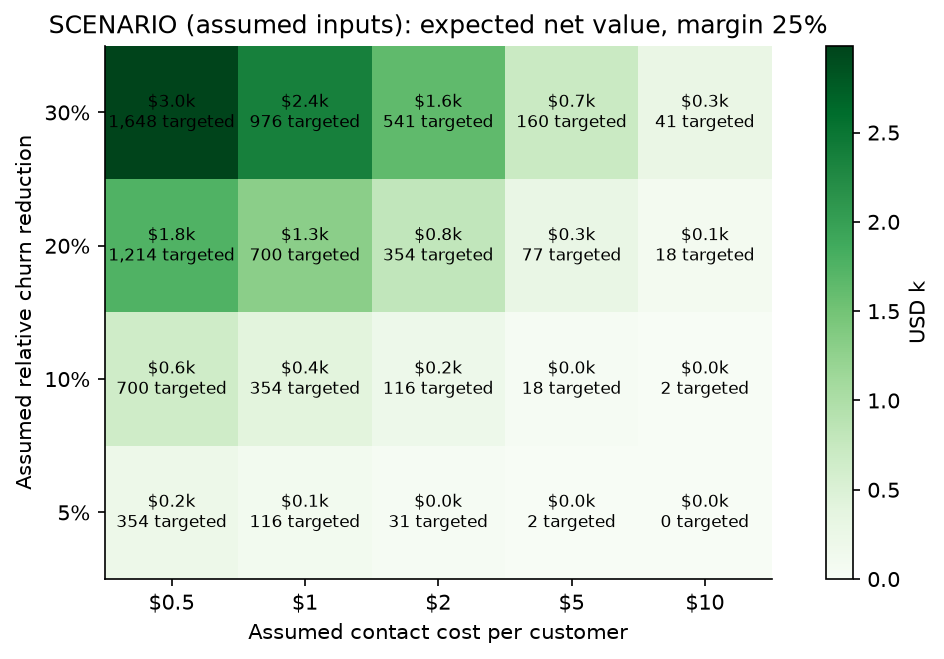

In [20]:
Image('docs/figures/targeting_sensitivity.png', width=700)

## Campaign analysis (observational, no causal claim)

In [21]:
pd.read_csv(art + 'campaign_outcomes_targeted.csv').round(3)

,risk_segment,targeted_in_window,n,n_churned,churn_rate,ci_lo,ci_hi,mean_future_spend
0,All scored,False,1077,71,0.066,0.053,0.082,228.545
1,All scored,True,1237,18,0.015,0.009,0.023,730.829
2,Low risk,False,75,0,0.000,0.000,0.049,730.586
3,Low risk,True,696,4,0.006,0.002,0.015,951.344
4,Medium risk,False,338,4,0.012,0.005,0.030,282.913
5,Medium risk,True,434,4,0.009,0.004,0.023,495.963
6,High risk,False,664,67,0.101,0.080,0.126,144.163
7,High risk,True,107,10,0.093,0.052,0.164,249.091


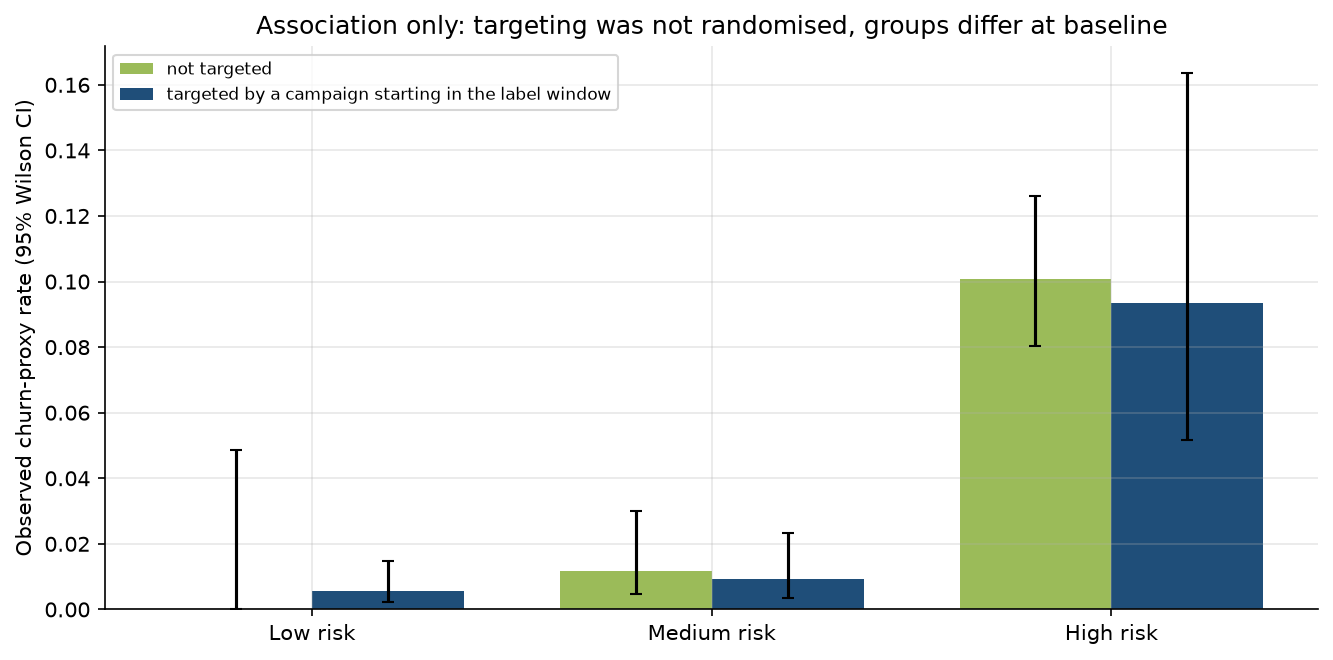

In [22]:
Image('docs/figures/campaign_outcomes.png', width=800)

## Demographics (partial coverage: 801 of 2,469 households)

In [23]:
pd.read_csv(art + 'demographics_coverage.csv').round(3).T

,0,1
group,With demographics,Without demographics
n_scored,801,1513
n_churned,2,87
churn_rate,0.002,0.058
mean_churn_prob,0.006,0.064
median_monetary_total,1981.26,579.1
median_frequency,52.0,20.0
mean_avg_basket_spend,37.388,29.061
mean_coupon_disc_share,0.006,0.004
mean_clv_12m,2960.655,1216.896


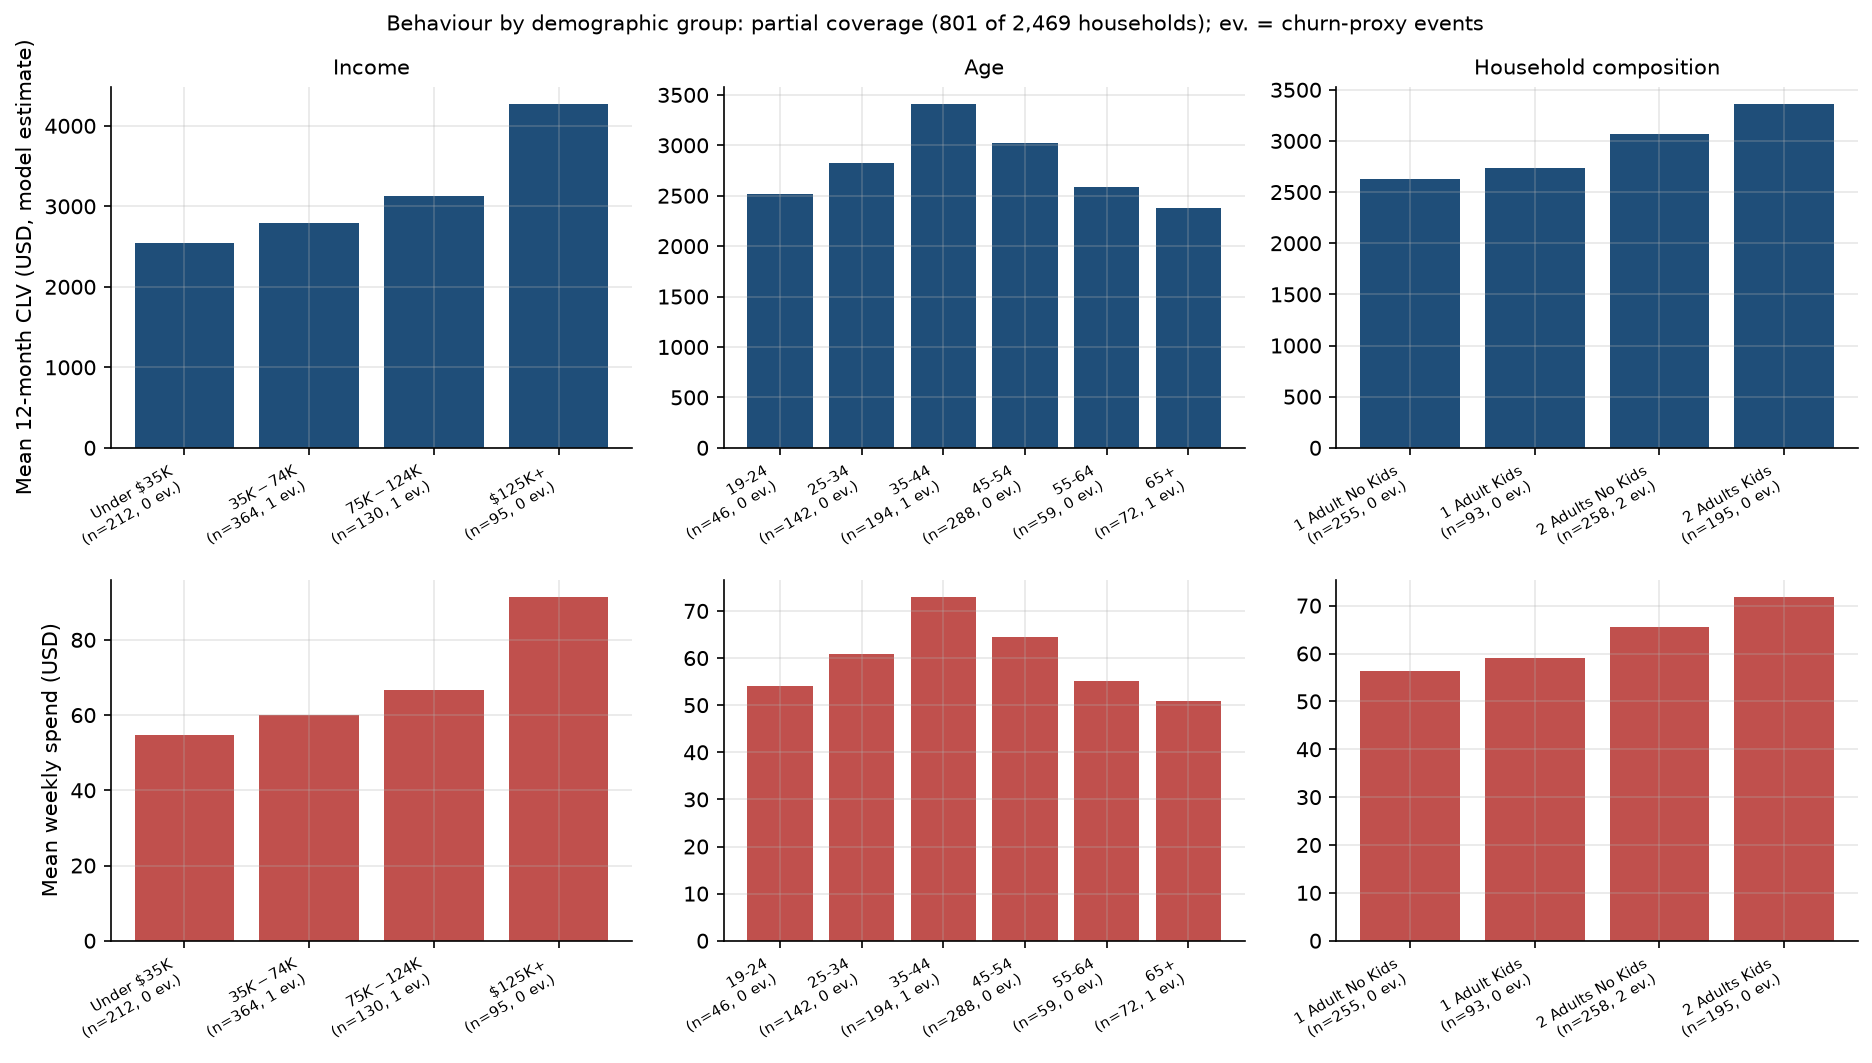

In [24]:
Image('docs/figures/demographics_profile.png', width=800)